In [16]:
import os
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

In [17]:
import os
import sys
import subprocess
from pathlib import Path

# Kaggle API 설치
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "kagglehub"
])

import kagglehub

# 데이터셋을 저장할 로컬 경로
DATA_ROOT = Path.cwd() / "kaggle_data"

# Kaggle 데이터셋 다운로드
dataset_path = Path(
    kagglehub.dataset_download(
        "tongpython/cat-and-dog",
        output_dir=str(DATA_ROOT)
    )
)

print(f"데이터셋 위치: {dataset_path}")

데이터셋 위치: c:\Users\wjdak\Desktop\연구생\intern\kaggle_data


In [18]:
from pathlib import Path

def find_directory(root, directory_name):
    matches = [
        path for path in root.rglob("*")
        if path.is_dir() and path.name.lower() == directory_name.lower()
    ]

    if not matches:
        raise FileNotFoundError(
            f"'{directory_name}' 디렉터리를 찾을 수 없습니다.\n"
            f"검색 위치: {root}"
        )

    return matches[0]

TRAIN_DIR = find_directory(dataset_path, "training_set")
TEST_DIR = find_directory(dataset_path, "test_set")

print(f"학습 데이터 경로: {TRAIN_DIR}")
print(f"테스트 데이터 경로: {TEST_DIR}")

학습 데이터 경로: c:\Users\wjdak\Desktop\연구생\intern\kaggle_data\training_set
테스트 데이터 경로: c:\Users\wjdak\Desktop\연구생\intern\kaggle_data\test_set


In [19]:
class CatDogDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        self.img_paths = []
        self.labels = []

        for root, _, files in os.walk(img_dir): #os.walk() 모든 파일 탐색 (dfs)
            for filename in files:
                if filename.lower().endswith('.jpg'): # jpg로 끝남?
                    full_path = os.path.join(root, filename)
                    lower_path = full_path.lower()

                    if 'cat' in lower_path:
                        self.img_paths.append(full_path)
                        self.labels.append(0)
                    elif 'dog' in lower_path:
                        self.img_paths.append(full_path)
                        self.labels.append(1)

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

In [20]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# 1. 학습용(Train)과 테스트용(Test) 데이터셋 각각 생성
train_dataset = CatDogDataset(img_dir=TRAIN_DIR, transform=transform)
test_dataset = CatDogDataset(img_dir=TEST_DIR, transform=transform)

# 2. 데이터로더 각각 생성
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)  # 학습용은 섞기(shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)   # 테스트용은 섞지 않음(shuffle=False)

print(f"학습 이미지 수: {len(train_dataset)}장")
print(f"테스트 이미지 수: {len(test_dataset)}장")

학습 이미지 수: 8005장
테스트 이미지 수: 2023장


In [21]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 32 * 32, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [22]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10
for epoch in range(epochs):
    # --- [1단계: 학습 (Training)] ---
    model.train()
    running_loss = 0.0

    for images, labels in train_loader: # train_loader 사용
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    # --- [2단계: 평가 (Evaluation / Testing)] ---
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad(): # 평가 시에는 그래디언트 계산을 안 해서 메모리/속도 이득
        for images, labels in test_loader: # test_loader 사용
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = (correct / total) * 100
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} | Test Accuracy: {accuracy:.2f}%")

Epoch [1/10] - Loss: 0.6381 | Test Accuracy: 68.81%
Epoch [2/10] - Loss: 0.5590 | Test Accuracy: 72.57%
Epoch [3/10] - Loss: 0.4910 | Test Accuracy: 70.64%
Epoch [4/10] - Loss: 0.4275 | Test Accuracy: 74.44%
Epoch [5/10] - Loss: 0.3678 | Test Accuracy: 74.25%
Epoch [6/10] - Loss: 0.2986 | Test Accuracy: 74.74%
Epoch [7/10] - Loss: 0.2089 | Test Accuracy: 73.70%
Epoch [8/10] - Loss: 0.1309 | Test Accuracy: 73.46%
Epoch [9/10] - Loss: 0.0776 | Test Accuracy: 74.05%
Epoch [10/10] - Loss: 0.0425 | Test Accuracy: 74.30%


findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Fon

학습 정확도: 99.05%
테스트 정확도: 74.30%
정확도 차이: 24.75%p


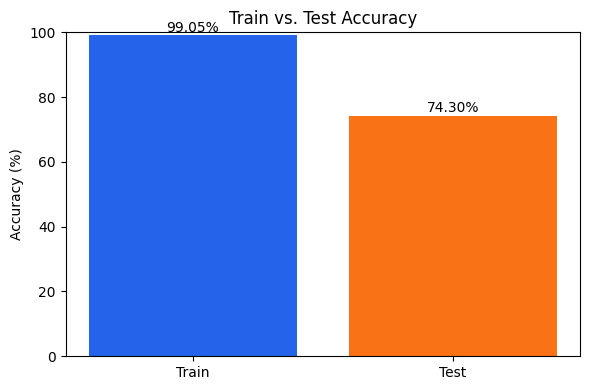

In [23]:
import torch
import matplotlib.pyplot as plt

def calculate_accuracy(model, data_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


train_accuracy = calculate_accuracy(model, train_loader, device)
test_accuracy = calculate_accuracy(model, test_loader, device)

print(f"학습 정확도: {train_accuracy:.2f}%")
print(f"테스트 정확도: {test_accuracy:.2f}%")
print(f"정확도 차이: {train_accuracy - test_accuracy:.2f}%p")

# 두 정확도를 막대그래프로 비교
names = ["Train", "Test"]
accuracies = [train_accuracy, test_accuracy]

plt.figure(figsize=(6, 4))
bars = plt.bar(names, accuracies, color=["#2563eb", "#f97316"])
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Train vs. Test Accuracy")

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

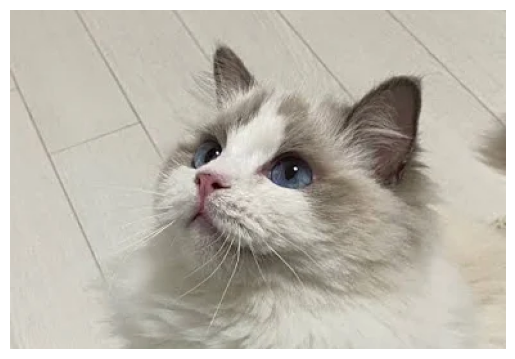

📷 입력 이미지: BB.jpg
🏷️  최종 예측 결과: Dog (강아지)


In [24]:
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt  # 👈 1. 이 라이브러리를 상단에 추가하세요!

# 1. 고양이/강아지 전용 라벨 매핑
labels_map = {
    0: "Cat (고양이)",
    1: "Dog (강아지)"
}

device = "cuda" if torch.cuda.is_available() else "cpu"

# 2. 고양이/강아지 이미지 전처리 파이프라인
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# 3. 이미지 불러오기 및 시각화
image_path = "BB.jpg"
img = Image.open(image_path).convert("RGB")
img_tensor = transform(img).unsqueeze(0).to(device)

# 👈 2. 기존 image.show() 대신 아래 코드로 대체합니다.
plt.imshow(img)
plt.axis('off') # 사진 주변의 눈금선(좌표축)을 숨깁니다.
plt.show()      # 현재 화면(노트북 셀 내부)에 이미지를 출력합니다.

# 4. 모델 추론 실행
model.eval()
with torch.no_grad():
    logits = model(img_tensor)
    pred_idx = logits.argmax(dim=1).item()

# 5. 결과 출력
print(f"📷 입력 이미지: {image_path}")
print(f"🏷️  최종 예측 결과: {labels_map.get(pred_idx, '알 수 없음')}")


In [25]:
import torch, random
import torch.nn.functional as F
import matplotlib.pyplot as plt

model = model.to(device)

@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    labels, preds, probs = [], [], []
    for x, y in loader:
        out = model(x.to(device))
        if isinstance(out, (tuple, list)):
            out = out[0]
        if out.dim() == 1 or out.shape[1] == 1:
            p1 = torch.sigmoid(out.view(-1)).cpu()
            p = torch.stack([1 - p1, p1], dim=1)
        else:
            p = F.softmax(out, dim=1).cpu()
        labels.append(y); preds.append(p.argmax(1)); probs.append(p)
    return torch.cat(labels), torch.cat(preds), torch.cat(probs)

labels, preds, probs = collect_predictions(model, test_loader, device)
class_names = getattr(test_dataset, "classes", ["cat", "dog"])
print(class_names, "정확도:", (labels == preds).float().mean().item())
print("출력 확인:", probs.shape, labels.shape)

['cat', 'dog'] 정확도: 0.7429559826850891
출력 확인: torch.Size([2023, 2]) torch.Size([2023])


'apt-get'��(��) ���� �Ǵ� �ܺ� ����, ������ �� �ִ� ���α׷�, �Ǵ�
��ġ ������ �ƴմϴ�.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_7016\4118154522.py:28: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_7016\4118154522.py:28: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
findfont: Font family 'NanumGothic' not found.
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel

사용 폰트: Malgun Gothic


findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Fon

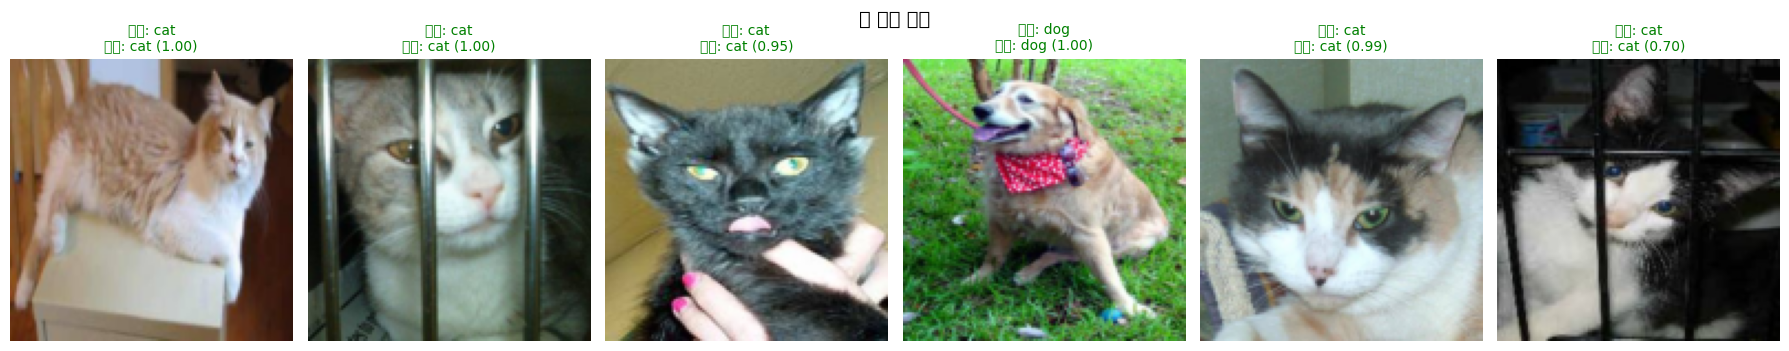

findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_7016\4118154522.py:28: UserWarning: Glyph 54869 (\N{HANGUL SYLLABLE HWAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_7016\4118154522.py:28: UserWarning: Glyph 49888 (\N{HANGUL SYLLABLE SIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\Creator

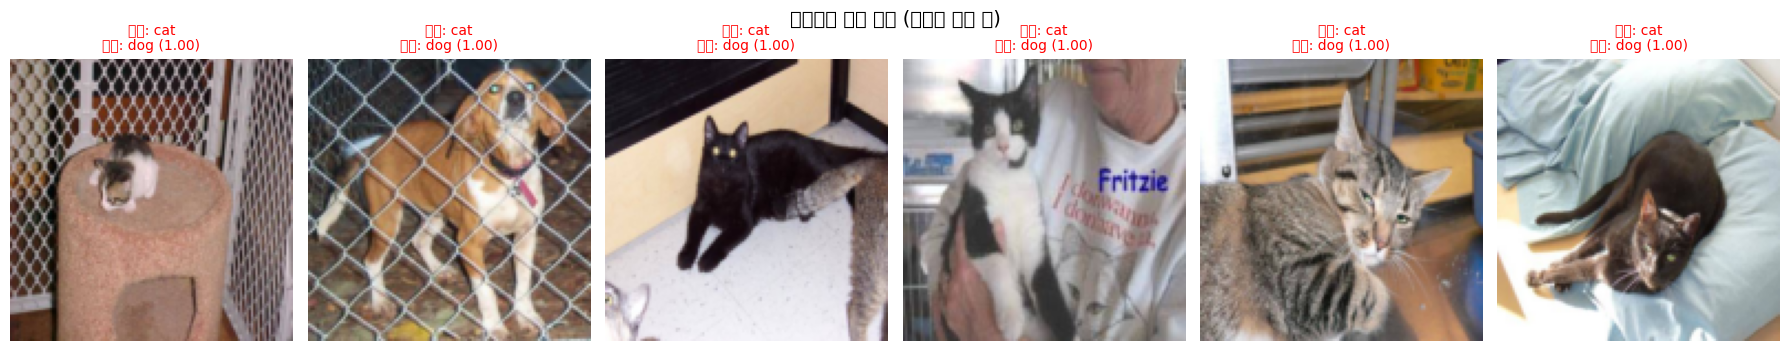

In [30]:
!apt-get -qq install -y fonts-nanum
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

installed = {f.name for f in fm.fontManager.ttflist}
for name in ["Malgun Gothic", "NanumGothic", "AppleGothic"]:
    if name in installed:
        plt.rc("font", family=name)
        print("사용 폰트:", name)
        break
else:
    print("한글 폰트를 찾지 못했습니다. 영어 라벨을 쓰세요.")

plt.rcParams["axes.unicode_minus"] = False
import matplotlib.font_manager as fm
plt.rc("font", family="NanumGothic")
def show_samples(idxs, title, n=6):
    idxs = idxs[:n]
    fig, axes = plt.subplots(1, len(idxs), figsize=(3 * len(idxs), 3.6))
    for ax, i in zip(axes if len(idxs) > 1 else [axes], idxs):
        img, _ = test_dataset[i]
        t, p = labels[i].item(), preds[i].item()
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.set_title(f"정답: {class_names[t]}\n예측: {class_names[p]} ({probs[i][p]:.2f})",
                     color="green" if t == p else "red", fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

wrong = (labels != preds).nonzero().flatten().tolist()
right = (labels == preds).nonzero().flatten().tolist()

wrong_sorted = sorted(wrong, key=lambda i: probs[i][preds[i]].item(), reverse=True)
show_samples(random.sample(right, 6), "잘 맞힌 예시")
show_samples(wrong_sorted, "확신하고 틀린 예시 (신뢰도 높은 순)")

findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_7016\3161531293.py:36: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_7016\3161531293.py:36: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout(); plt.show()
findfont: Font family 'NanumGothic' not found.
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_7016\3161531293.py:36: UserWarning: 

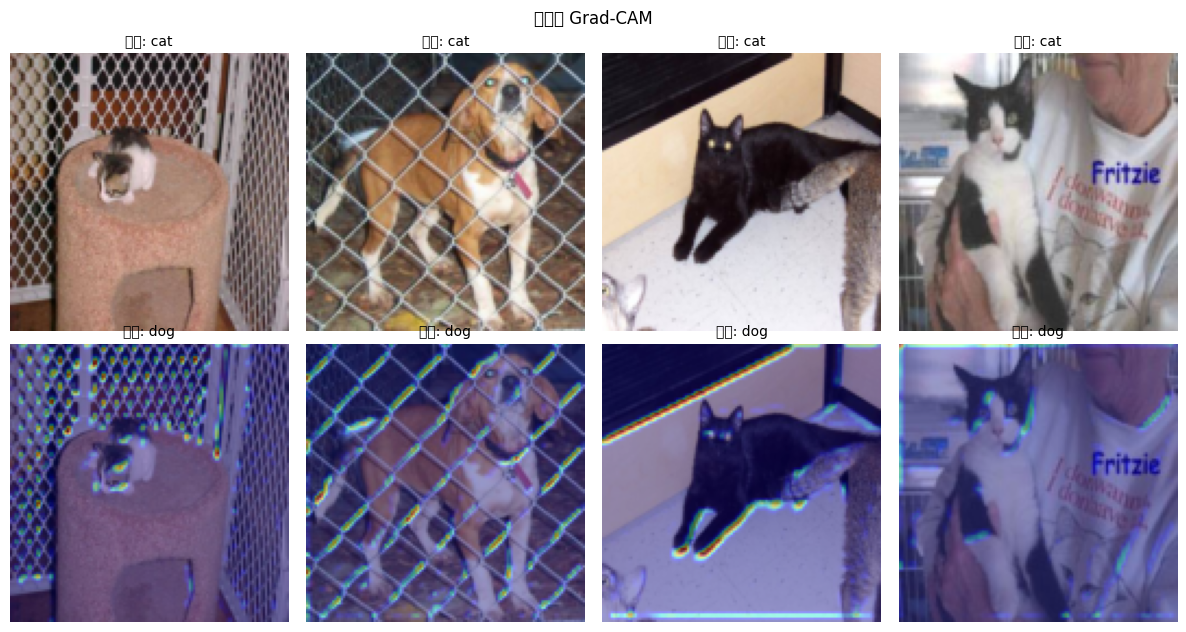

findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Font family 'NanumGothic' not found.
findfont: Fon

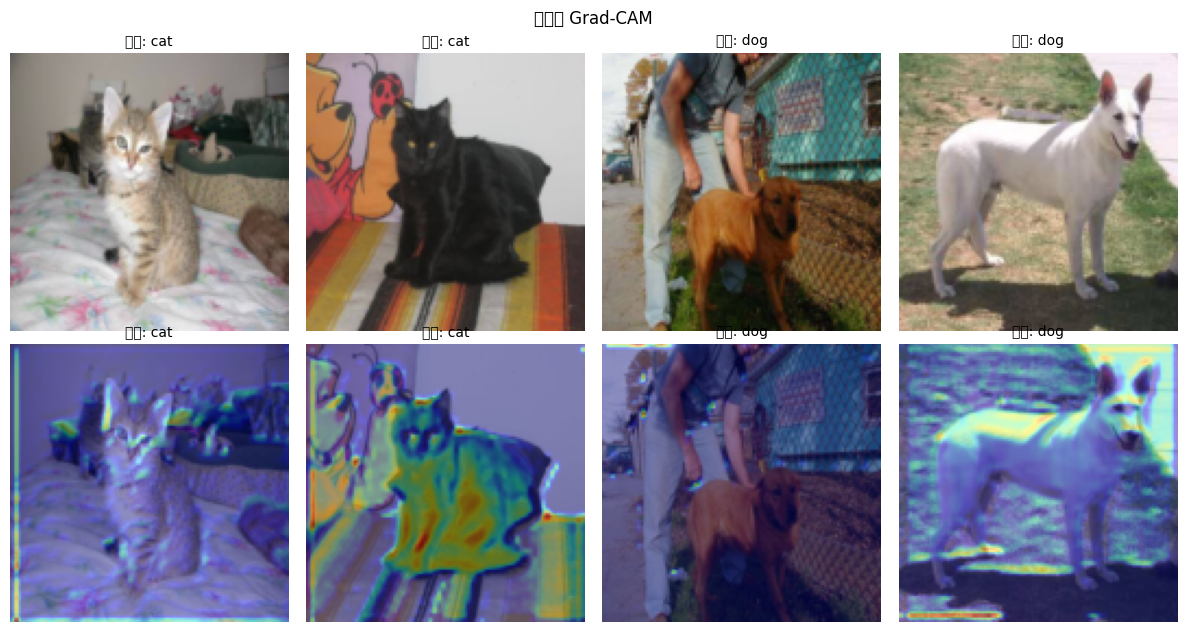

In [27]:
import torch.nn as nn
import numpy as np

target_layer = [m for m in model.modules() if isinstance(m, nn.Conv2d)][-1]

def grad_cam(x, class_idx=None):
    acts, grads = [], []
    def fwd_hook(m, i, o):
        acts.append(o); o.register_hook(lambda g: grads.append(g))
    h = target_layer.register_forward_hook(fwd_hook)
    model.eval()
    out = model(x.unsqueeze(0).to(device))
    if class_idx is None:
        class_idx = out.argmax(1).item()
    model.zero_grad()
    out[0, class_idx].backward()
    h.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[1:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam.detach().cpu()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.numpy(), class_idx

def show_gradcam(idxs, title, n=4):
    idxs = idxs[:n]
    fig, axes = plt.subplots(2, len(idxs), figsize=(3 * len(idxs), 6.4), squeeze=False)
    for k, i in enumerate(idxs):
        img, _ = test_dataset[i]
        cam, c = grad_cam(img)
        axes[0, k].imshow(img.permute(1, 2, 0).numpy()); axes[0, k].axis("off")
        axes[0, k].set_title(f"정답: {class_names[labels[i]]}", fontsize=10)
        axes[1, k].imshow(img.permute(1, 2, 0).numpy())
        axes[1, k].imshow(cam, cmap="jet", alpha=0.4); axes[1, k].axis("off")
        axes[1, k].set_title(f"예측: {class_names[c]}", fontsize=10)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_gradcam(wrong_sorted, "오분류 Grad-CAM")
show_gradcam(random.sample(right, 4), "정분류 Grad-CAM")